# **Exercises Chapter 05**

# Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

from ISLP import load_data
from ISLP.models import summarize
from ISLP.models import (ModelSpec as MS, summarize, poly)
from ISLP.models import sklearn_sm

from sklearn.linear_model import LinearRegression

from functools import partial
from sklearn.model_selection import (cross_validate, KFold, ShuffleSplit)
from sklearn.base import clone



## **Cross-Validation and the Bootstrap**

Load the file Ch05-Py-1.csv and load it into a DataFrame called "df". Fit a linear regression model with response "y" and features "X1" and "X2". What is the standard error for $\beta_1$?

In [2]:
df = pd.read_csv("Ch05-Py-1.csv")
df.head()

,X1,X2,y
0,1.297720,0.805921,0.298968
1,1.267323,0.799034,0.318134
2,1.236882,0.792169,0.337201
3,1.206317,0.785296,0.356121
4,1.175553,0.778385,0.374842


In [3]:
y = df["y"]
X = df.drop(columns=["y"])
X = sm.add_constant(X)
model = sm.OLS(y, X)
results = model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.117
Model:                            OLS   Adj. R-squared:                  0.115
Method:                 Least Squares   F-statistic:                     66.14
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           1.06e-27
Time:                        14:47:51   Log-Likelihood:                -810.66
No. Observations:                1000   AIC:                             1627.
Df Residuals:                     997   BIC:                             1642.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2658      0.020     13.372      0.0

In [4]:
print(summarize(results))

         coef  std err       t  P>|t|
const  0.2658    0.020  13.372    0.0
X1     0.1453    0.026   5.604    0.0
X2     0.3134    0.029  10.722    0.0


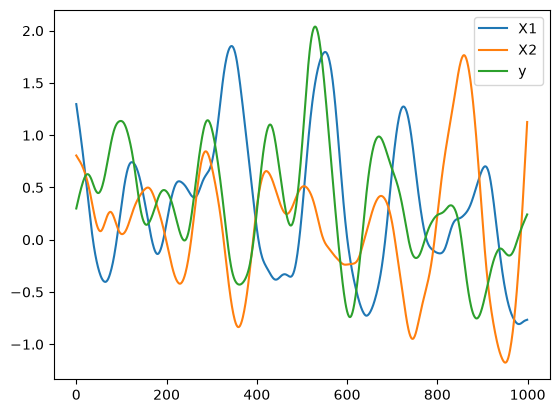

In [5]:
df.plot();

Now, use the (standard) bootstrap to estimate $\text{s.e.}(\hat{\beta_1})$. To within 10%, what do you get?

In [18]:
def boot_OLS(model_matrix, response, D, idx):
    D_ = D.loc[idx]
    Y_ = D_[response]
    X_ = clone(model_matrix).fit_transform(D_)
    return sm.OLS(Y_, X_).fit().params

In [19]:
def boot_SE(func,
            D,
            n=None,
            B=1000,
            seed=0):
    rng = np.random.default_rng(seed)
    first_, second_ = 0, 0
    n = n or D.shape[0]
    for _ in range(B):
        idx = rng.choice(D.index,
                         n,
                         replace=True)
        value = func(D, idx)
        first_ += value
        second_ += value**2
    return np.sqrt(second_ / B - (first_ / B)**2)


In [8]:
hp_func = partial(boot_OLS, MS(["X1", "X2"]), 'y')


In [14]:
new_rows = np.r_[slice(100,200), slice(400,500), slice(100, 200), slice(900,1000), slice(300,400), slice(0, 100), slice(0,100), slice(800,900), slice(200,300), slice(700, 800)]
new_df = df.iloc[new_rows]
new_df

,X1,X2,y
100,0.327028,0.054913,1.135742
101,0.358675,0.053752,1.134353
102,0.389793,0.053699,1.132062
103,0.420223,0.054714,1.128780
104,0.449808,0.056759,1.124419
...,...,...,...
795,-0.114930,0.045319,0.216452
796,-0.117514,0.082170,0.221325
797,-0.119879,0.119577,0.225746
798,-0.122021,0.157421,0.229727


In [16]:
rng = np.random.default_rng(0)
np.array([hp_func(new_df,
          rng.choice(100,
                     10,
                     replace=True)) for _ in range(10)])


array([[ 0.46034136, -0.58640514,  0.79395396],
       [ 0.72606806,  1.30792924,  2.37769349],
       [ 0.49976698, -0.52599419,  0.63432945],
       [ 0.43006951, -0.59459041,  0.86360446],
       [ 0.01692452, -0.83617917,  1.71587231],
       [ 1.07488765,  0.30610066, -1.24806888],
       [ 0.8434425 ,  0.0417119 , -0.35453187],
       [ 1.01222971,  0.49898938, -1.35949436],
       [-0.07851791, -1.03320855,  2.05816144],
       [ 1.22365715,  0.37815998, -1.54752879]])

In [21]:
hp_se = boot_SE(hp_func,
                new_df,
                B=1000,
                seed=10)
hp_se


intercept    0.013908
X1           0.019047
X2           0.030198
dtype: float64

# Block bootstrap implementation

In [ ]:
# load data
df = pd.read_csv("Ch05-Py-1.csv")

# number of bootstrap replications
B = 1000

beta1_boot = []

rng = np.random.default_rng(1)

for b in range(B):

    # choose 10 blocks with replacement
    blocks = rng.choice(10, size=10, replace=True)

    # concatenate the selected blocks
    rows = np.r_[
        tuple(
            slice(100*i, 100*(i+1))
            for i in blocks
        )
    ]

    boot_df = df.iloc[rows]

    # refit regression
    X = sm.add_constant(boot_df[["X1", "X2"]])
    y = boot_df["y"]

    fit = sm.OLS(y, X).fit()

    beta1_boot.append(fit.params["X1"])

# block bootstrap estimate of SE(beta1)
se_block = np.std(beta1_boot, ddof=1)

print(se_block)

0.19887604073034737


# Plot plane of Sales x TV x Radio advertising

In [ ]:
# Load data
df = pd.read_csv('Advertising.csv')

# Fit model for smooth surface
X = df[['TV', 'radio']]
y = df['sales']
model = LinearRegression()
model.fit(X, y)

# Create grid for surface plot
tv_range = np.linspace(df['TV'].min(), df['TV'].max(), 30)
radio_range = np.linspace(df['radio'].min(), df['radio'].max(), 30)
TV_grid, Radio_grid = np.meshgrid(tv_range, radio_range)

# Predict sales on grid
Sales_grid = model.predict(np.c_[TV_grid.ravel(), Radio_grid.ravel()]).reshape(TV_grid.shape)

# Create 3D plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Surface plot of fitted regression model
surf = ax.plot_surface(TV_grid, Radio_grid, Sales_grid, cmap='viridis', alpha=0.6, edgecolor='none')

# Scatter plot of actual data
ax.scatter(df['TV'], df['radio'], df['sales'], color='red', s=30, label='Actual Sales')

ax.set_xlabel('TV Spend ($)')
ax.set_ylabel('Radio Spend ($)')
ax.set_zlabel('Sales')
ax.set_title('Sales as a Function of TV and Radio Advertising')
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5, label='Predicted Sales')
ax.legend()

plt.show()

# Credit Data set

In [ ]:
credit = load_data("Credit")
credit.head()

In [ ]:
credit.info()

In [ ]:
colunas = ["Balance", 'Age', 'Cards', 'Education', 'Income', 'Limit', 'Rating']
pd.plotting.scatter_matrix(credit[colunas], figsize=(12, 10))
plt.show()

In [ ]:
credit.columns

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 8))

axes[0, 0].hist(college["Top10perc"], bins=35)
axes[0, 0].set_xlabel("Top10perc")

axes[0, 1].hist(college["PhD"], bins=35)
axes[0, 1].set_xlabel("PhD")

axes[1, 0].hist(college["Accept"], bins=35)
axes[1, 0].set_xlabel("Accept")

axes[1, 1].hist(college["Enroll"], bins=35)
axes[1, 1].set_xlabel("Enroll")

plt.suptitle("Histograms of College Data")
plt.show()

# **Working with the Auto dataset**

In [ ]:
auto = load_data('Auto')
auto.dropna(inplace=True)
auto.head()

In [ ]:
for x in ['cylinders', 'year', 'origin']:
    print(f"{x}: {auto[x].unique()}", "\n")

In [ ]:
for x in auto.columns:
    print(f"Max of {x}: {auto[x].max():.2f}")
    print(f"Min of {x}: {auto[x].min():.2f}")
    print(f"Mean of {x}: {auto[x].mean():.2f}")
    print(f"Std of {x}: {auto[x].std():.2f}\n")

In [ ]:
mask = [(i < 10) or (i > 84) for i in range(len(auto))]
auto_filtered = auto.iloc[mask]

for x in auto_filtered.columns:
    print(f"Max of {x}: {auto_filtered[x].max():.2f}")
    print(f"Min of {x}: {auto_filtered[x].min():.2f}")
    print(f"Mean of {x}: {auto_filtered[x].mean():.2f}")
    print(f"Std of {x}: {auto_filtered[x].std():.2f}\n")



In [ ]:
pd.plotting.scatter_matrix(auto, figsize=(10, 10));

# **Working with the Boston dataset**

In [ ]:
boston = load_data('Boston')
boston.head()

In [ ]:
boston.info()

In [ ]:
boston["chas"].sum()

What is the median pupil-teacher ratio among the towns in this
data set?

In [ ]:
resp = boston["ptratio"].median()
print(f"The median pupil-teacher ratio in the Boston dataset is: {resp:.2f}")

Which suburb of Boston has lowest median value of owner-occupied homes? What are the values of the other predictors for that suburb, and how do those values compare to the overall ranges for those predictors? Comment on your findings.

In [ ]:
boston["age"].median()

In [ ]:
import scipy.stats as stats

# Given parameters
beta1_hat = 0.5
se_beta1 = 0.2
alpha = 0.05

# Critical Z-value for a two-tailed test at alpha = 0.05
z_crit = stats.norm.ppf(1 - alpha / 2)

# Calculate upper and lower bounds for b (95% CI)
b_max = beta1_hat + z_crit * se_beta1
b_min = beta1_hat - z_crit * se_beta1

print(f"Critical Z-value: {z_crit:.4f}")
print(f"Non-rejection region for b: [{b_min:.4f}, {b_max:.4f}]")
print(f"Largest value of b (2 significant digits): {b_max:.2g}")

In [ ]:
stats.norm.sf

In [ ]:
def logReg(beta0, beta1, beta2, x1, x2):
    eq = beta0 + beta1 * x1 + beta2 * x2
    return np.exp(eq) / (1 + np.exp(eq))

In [ ]:
x = logReg(-6, 0.05, 1, 40, 3.5)
print(f"Prob = {x:.2f}")

In [ ]:
beta0 = -6
beta1 = 0.05
beta2 = 1
x2 = 3.5
x1 = (-beta0 - beta2 * x2) / beta1
print(x1)